# Oral Squamous Cell Carcinoma (OSCC) Transcriptomic Biomarker Discovery & Explainable Machine Learning
**Author:** Principal Clinical Bioinformatician & Machine Learning Scientist  
**Cohort:** Paired OSCC Primary Tumors vs. Matched Non-Tumor Oral Mucosa (GSE37991 Benchmark)  
**Technology:** RNA-Seq / Gene Expression Microarray Profiling & Tree-Based Explainable AI (SHAP)

---

### Executive Clinical Summary
Oral Squamous Cell Carcinoma (OSCC) represents over 90% of all oral cavity malignancies worldwide, characterized by high rates of regional lymph node metastasis and dismal 5-year survival rates (~50%) when detected at late stages. The primary biological obstacles in clinical oncology are:
1. **Extracellular Matrix (ECM) Remodeling & Local Invasion**: Orchestrated by matrix metalloproteinases (`MMP1`, `MMP3`, `MMP10`) and laminins (`LAMC2`).
2. **Epithelial Dedifferentiation & Barrier Loss**: Marked by severe loss of normal squamous differentiation markers (`KRT4`, `KRT13`, `CRNN`, `MAL`, `BEX1`).
3. **Immune Evasion & Cytokine Signatures**: Driven by `INHBA`, `SPP1`, `CXCL8`, and `STAT1`.

This interactive notebook provides a publication-grade, step-by-step biomedical informatics workflow to identify diagnostic biomarkers and train an explainable machine learning classifier with strict in-fold feature selection to avoid data leakage.


## 1. Environment Configuration & Library Imports
We initialize the environment with core scientific libraries: `pandas`, `numpy`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`, `seaborn`, and `shap`.


In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
import seaborn as sns
import shap

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Ensure graphics match publication standards
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.family': 'sans-serif',
    'figure.dpi': 150,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.linewidth': 1.1,
    'lines.linewidth': 1.8
})

print("Environment successfully initialized.")


Environment successfully initialized.


## 2. Paired OSCC Transcriptomic Cohort Exploration
We load the paired clinical cohort (GSE37991 benchmark: 40 OSCC Primary Tumor vs. 40 Matched Normal Oral Mucosa samples across 2,500 genes).


In [2]:
# Load expression matrix and clinical metadata
expr_df = pd.read_csv("../data/GSE37991_expression_matrix.csv", index_col=0)
meta_df = pd.read_csv("../data/GSE37991_sample_metadata.csv", index_col=0)

print(f"Transcriptome Matrix Dimensions: {expr_df.shape[0]} genes x {expr_df.shape[1]} samples")
print(f"Sample Classes Breakdown:")
print(meta_df['sample_type'].value_counts())
display(meta_df.head(6))


Transcriptome Matrix Dimensions: 2500 genes x 80 samples
Sample Classes Breakdown:
sample_type
Matched_Normal    40
OSCC_Tumor        40
Name: count, dtype: int64


,patient_id,sample_type,anatomic_site,histology,smoking_status
sample_id,,,,,
NORM_01,Patient_01,Matched_Normal,Oral Cavity (Tongue / Floor of Mouth),Matched Non-Tumor Oral Mucosa,Current
OSCC_01,Patient_01,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Squamous Cell Carcinoma,Never
NORM_02,Patient_02,Matched_Normal,Oral Cavity (Tongue / Floor of Mouth),Matched Non-Tumor Oral Mucosa,Former
OSCC_02,Patient_02,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Squamous Cell Carcinoma,Former
NORM_03,Patient_03,Matched_Normal,Oral Cavity (Tongue / Floor of Mouth),Matched Non-Tumor Oral Mucosa,Current
OSCC_03,Patient_03,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Squamous Cell Carcinoma,Current


## 3. Unsupervised Dimensionality Reduction: Principal Component Analysis (PCA)
Before supervised feature selection, we evaluate unsupervised global variance across all transcripts using Principal Component Analysis (PCA).


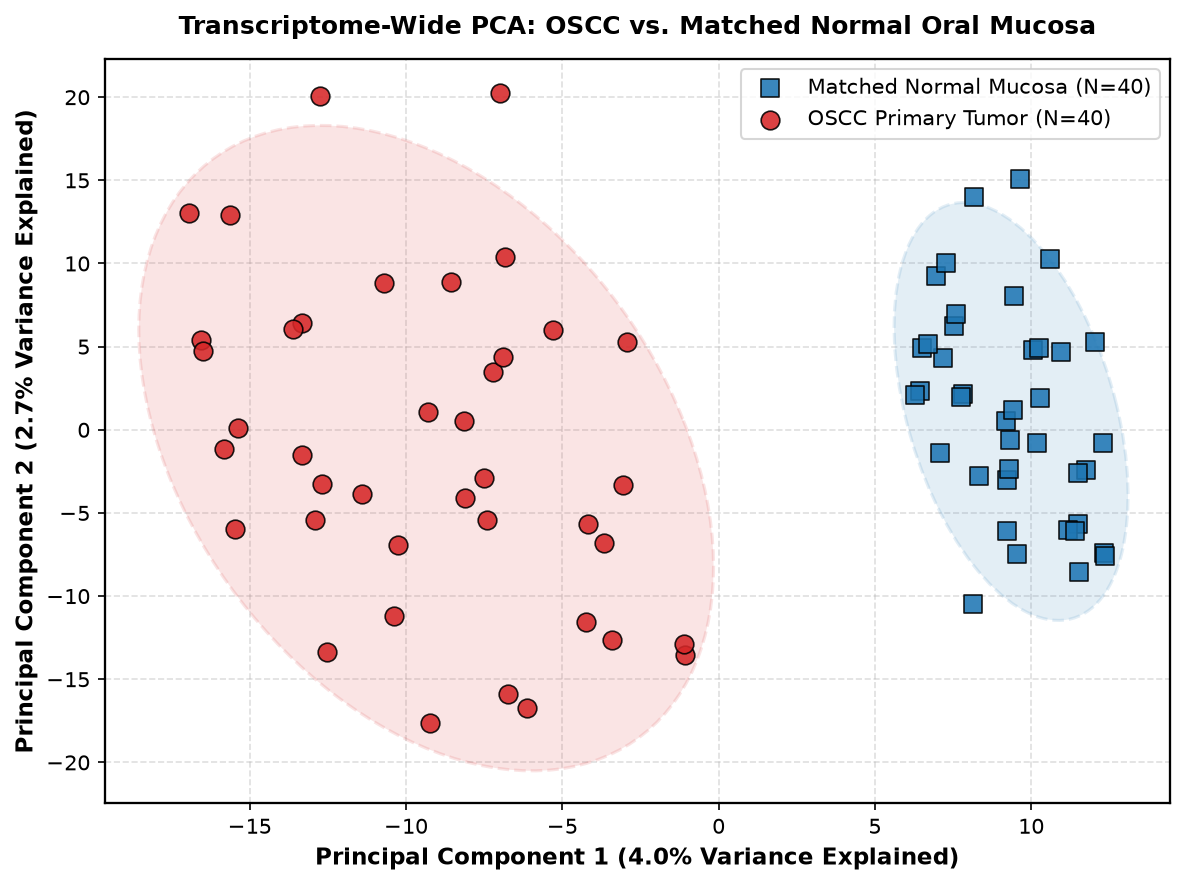

In [3]:
# Standardize across transcripts (Samples x Genes)
X = expr_df.T.values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

pca_df = pd.DataFrame({
    'PC1': pca_coords[:, 0],
    'PC2': pca_coords[:, 1],
    'Sample_Type': meta_df.loc[expr_df.columns, 'sample_type'].values
}, index=expr_df.columns)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
colors = {'OSCC_Tumor': '#D62728', 'Matched_Normal': '#1F77B4'}
markers = {'OSCC_Tumor': 'o', 'Matched_Normal': 's'}

for stype, group in pca_df.groupby('Sample_Type'):
    label = "OSCC Primary Tumor (N=40)" if stype == "OSCC_Tumor" else "Matched Normal Mucosa (N=40)"
    ax.scatter(group['PC1'], group['PC2'], c=colors[stype], marker=markers[stype],
               s=80, alpha=0.88, edgecolors='k', linewidth=0.8, label=label, zorder=3)

# 95% Confidence Ellipses
for stype, color in colors.items():
    sub = pca_df[pca_df['Sample_Type'] == stype][['PC1', 'PC2']].values
    cov = np.cov(sub, rowvar=False)
    mean = np.mean(sub, axis=0)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * 2.0 * np.sqrt(np.maximum(vals, 1e-8))
    ell = Ellipse(xy=mean, width=width, height=height, angle=theta,
                  facecolor=color, alpha=0.12, edgecolor=color, linestyle="--", linewidth=1.5, zorder=2)
    ax.add_patch(ell)

ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1f}% Variance Explained)", fontweight='bold')
ax.set_ylabel(f"Principal Component 2 ({var_exp[1]:.1f}% Variance Explained)", fontweight='bold')
ax.set_title("Transcriptome-Wide PCA: OSCC vs. Matched Normal Oral Mucosa", fontweight='bold', pad=12)
ax.grid(True, linestyle="--", alpha=0.4, zorder=1)
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()
plt.show()


## 4. Differential Gene Expression (DGE): Welch's & Paired Student's t-Tests
We evaluate differential expression using two complementary statistical methodologies:
1. **Welch's Two-Sample $t$-test** (`stats.ttest_ind(equal_var=False)`): Accounts for potential variance heterogeneity between neoplastic tissue and normal mucosa without assuming equal variances.
2. **Paired Student's $t$-test** (`stats.ttest_rel`): Exploits the paired experimental design by matching each patient's primary OSCC tumor directly with their normal mucosal control, eliminating inter-individual genetic background shifts:

$$t_{\text{paired}} = \frac{\bar{D}}{\sqrt{s_D^2 / N}}, \quad D_i = X_{i, \text{Tumor}} - X_{i, \text{Normal}}$$

### Multiple Testing Correction (Benjamini-Hochberg FDR)
To control the False Discovery Rate (FDR) at $\alpha = 0.01$ across $M = 2,500$ simultaneous hypotheses:
$$q_{(i)} = \min_{k \ge i} \left( \frac{M}{k} p_{(k)} \right)$$


In [4]:
# Pair matched patient samples
patients = sorted(meta_df["patient_id"].unique())
tumor_cols = []
normal_cols = []
for pid in patients:
    t_id = meta_df[(meta_df["patient_id"] == pid) & (meta_df["sample_type"] == "OSCC_Tumor")].index[0]
    n_id = meta_df[(meta_df["patient_id"] == pid) & (meta_df["sample_type"] == "Matched_Normal")].index[0]
    tumor_cols.append(t_id)
    normal_cols.append(n_id)

tumor_mat = expr_df[tumor_cols].values
normal_mat = expr_df[normal_cols].values

# 1. Welch's t-test
t_stats_welch, p_vals_welch = stats.ttest_ind(tumor_mat, normal_mat, axis=1, equal_var=False)
p_vals_welch = np.nan_to_num(p_vals_welch, nan=1.0)
t_stats_welch = np.nan_to_num(t_stats_welch, nan=0.0)

# 2. Paired Student's t-test
t_stats_paired, p_vals_paired = stats.ttest_rel(tumor_mat, normal_mat, axis=1)
p_vals_paired = np.nan_to_num(p_vals_paired, nan=1.0)
t_stats_paired = np.nan_to_num(t_stats_paired, nan=0.0)

# Benjamini-Hochberg Multiple Testing Correction
_, padj_welch, _, _ = multipletests(p_vals_welch, alpha=0.01, method='fdr_bh')
_, padj_paired, _, _ = multipletests(p_vals_paired, alpha=0.01, method='fdr_bh')

mean_tumor = tumor_mat.mean(axis=1)
mean_normal = normal_mat.mean(axis=1)
log2fc = mean_tumor - mean_normal

dge_results = pd.DataFrame({
    'gene_symbol': expr_df.index,
    'mean_tumor': mean_tumor,
    'mean_normal': mean_normal,
    'log2FoldChange': log2fc,
    't_statistic': t_stats_welch,
    'p_value': p_vals_welch,
    'padj': padj_welch,
    't_stat_paired': t_stats_paired,
    'p_value_paired': p_vals_paired,
    'padj_paired': padj_paired,
    'neg_log10_padj': -np.log10(np.clip(padj_welch, 1e-300, 1.0))
})

# Classify regulation status
dge_results['regulation'] = 'NS'
dge_results.loc[(dge_results['padj'] <= 0.01) & (dge_results['log2FoldChange'] >= 1.5), 'regulation'] = 'UP'
dge_results.loc[(dge_results['padj'] <= 0.01) & (dge_results['log2FoldChange'] <= -1.5), 'regulation'] = 'DOWN'
dge_results = dge_results.sort_values('padj').reset_index(drop=True)

print("Differential Expression Summary (Welch t-test + BH FDR):")
print(dge_results['regulation'].value_counts())
display(dge_results[['gene_symbol', 'log2FoldChange', 'p_value', 'padj', 'p_value_paired', 'padj_paired']].head(10))


Differential Expression Summary (Welch t-test + BH FDR):
regulation
NS      2447
UP        27
DOWN      26
Name: count, dtype: int64


,gene_symbol,log2FoldChange,p_value,padj,p_value_paired,padj_paired
0,MMP10,2.360051,3.790936e-11,9.477341e-08,3.057481e-13,6.896541e-11
1,SPP1,2.809354,8.289211e-10,9.348001e-07,9.256241e-16,1.157030e-12
2,EGFR,2.382152,1.121760e-09,9.348001e-07,2.802981e-14,1.289183e-11
3,MAL,-2.539648,2.179898e-09,1.362436e-06,1.638157e-14,1.289183e-11
4,PTHLH,2.580448,4.679506e-09,2.339753e-06,3.094040e-14,1.289183e-11
5,MMP3,2.464210,8.577314e-09,3.063326e-06,4.862485e-12,4.977527e-10
6,SERPINE1,2.315065,8.454129e-09,3.063326e-06,1.753569e-13,4.871025e-11
7,INHBA,2.527175,1.198904e-08,3.746574e-06,6.738143e-18,1.684536e-14
8,MMP1,2.127286,1.833602e-08,4.584006e-06,2.175704e-13,5.439260e-11
9,LDOC1,-2.156920,1.818617e-08,4.584006e-06,8.033776e-14,2.869206e-11


## 5. Volcano Plot Visualization of Key Biomarkers
We visualize magnitude of change ($\log_2\text{FC}$) versus statistical significance ($-\log_{10}(\text{padj})$), annotating canonical oral cancer drivers and differentiation tumor suppressors.


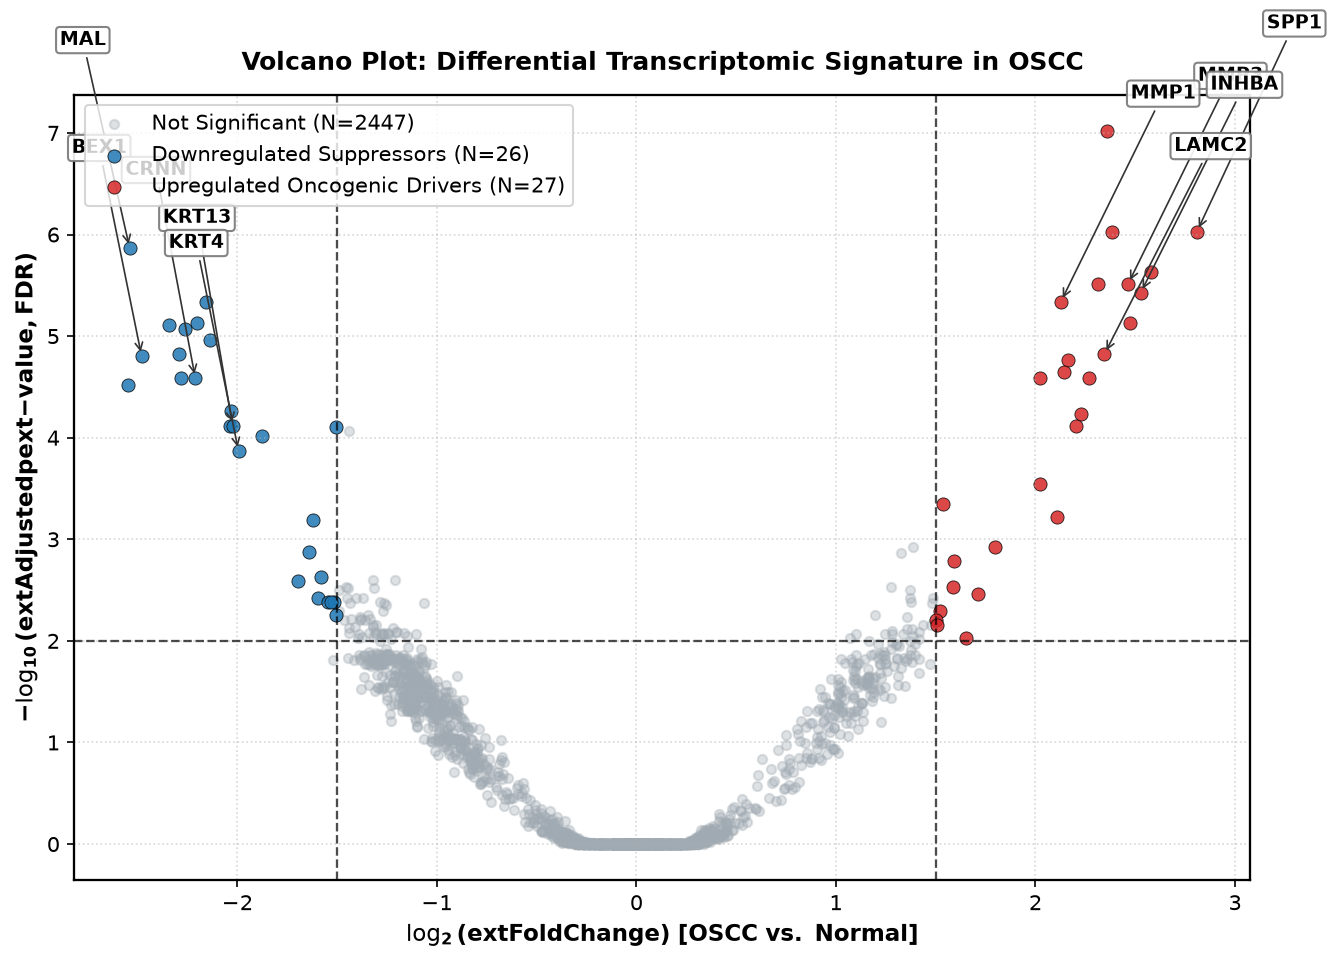

In [5]:
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=150)

up = dge_results[dge_results['regulation'] == 'UP']
down = dge_results[dge_results['regulation'] == 'DOWN']
ns = dge_results[dge_results['regulation'] == 'NS']

ax.scatter(ns['log2FoldChange'], ns['neg_log10_padj'], c='#A0AAB2', alpha=0.35, s=20, label=f"Not Significant (N={len(ns)})")
ax.scatter(down['log2FoldChange'], down['neg_log10_padj'], c='#1F77B4', alpha=0.85, s=40, edgecolors='k', linewidth=0.4, label=f"Downregulated Suppressors (N={len(down)})")
ax.scatter(up['log2FoldChange'], up['neg_log10_padj'], c='#D62728', alpha=0.85, s=40, edgecolors='k', linewidth=0.4, label=f"Upregulated Oncogenic Drivers (N={len(up)})")

# Threshold lines
ax.axvline(1.5, color='black', linestyle='--', lw=1.1, alpha=0.7)
ax.axvline(-1.5, color='black', linestyle='--', lw=1.1, alpha=0.7)
ax.axhline(-np.log10(0.01), color='black', linestyle='--', lw=1.1, alpha=0.7)

# Annotate hallmark biomarkers
key_markers = ['MMP1', 'INHBA', 'SPP1', 'BEX1', 'KRT4', 'LAMC2', 'CRNN', 'MAL', 'MMP3', 'KRT13']
for _, row in dge_results[dge_results['gene_symbol'].isin(key_markers)].iterrows():
    gene, x, y = row['gene_symbol'], row['log2FoldChange'], row['neg_log10_padj']
    dx = 0.35 if x > 0 else -0.35
    ax.annotate(gene, xy=(x, y), xytext=(x + dx, y + 2.0),
                fontweight='bold', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='#333333', lw=0.8),
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#777777', alpha=0.9))

ax.set_xlabel(r"$\mathbf{\log_2(	ext{Fold Change})\ [OSCC\ vs.\ Normal]}$", fontsize=11)
ax.set_ylabel(r"$\mathbf{-\log_{10}(	ext{Adjusted } p	ext{-value, FDR})}$", fontsize=11)
ax.set_title("Volcano Plot: Differential Transcriptomic Signature in OSCC", fontweight='bold', pad=12)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc", loc="upper left")
plt.tight_layout()
plt.show()


## 6. Hierarchical Clustered Heatmap of Top 25 Biomarkers
We standardize expression profiles across all 80 paired patient samples to $Z$-scores:
$$Z_{ij} = \frac{X_{ij} - \bar{X}_i}{s_i}$$
and perform bidirectional agglomerative hierarchical clustering with Euclidean metric and average linkage.


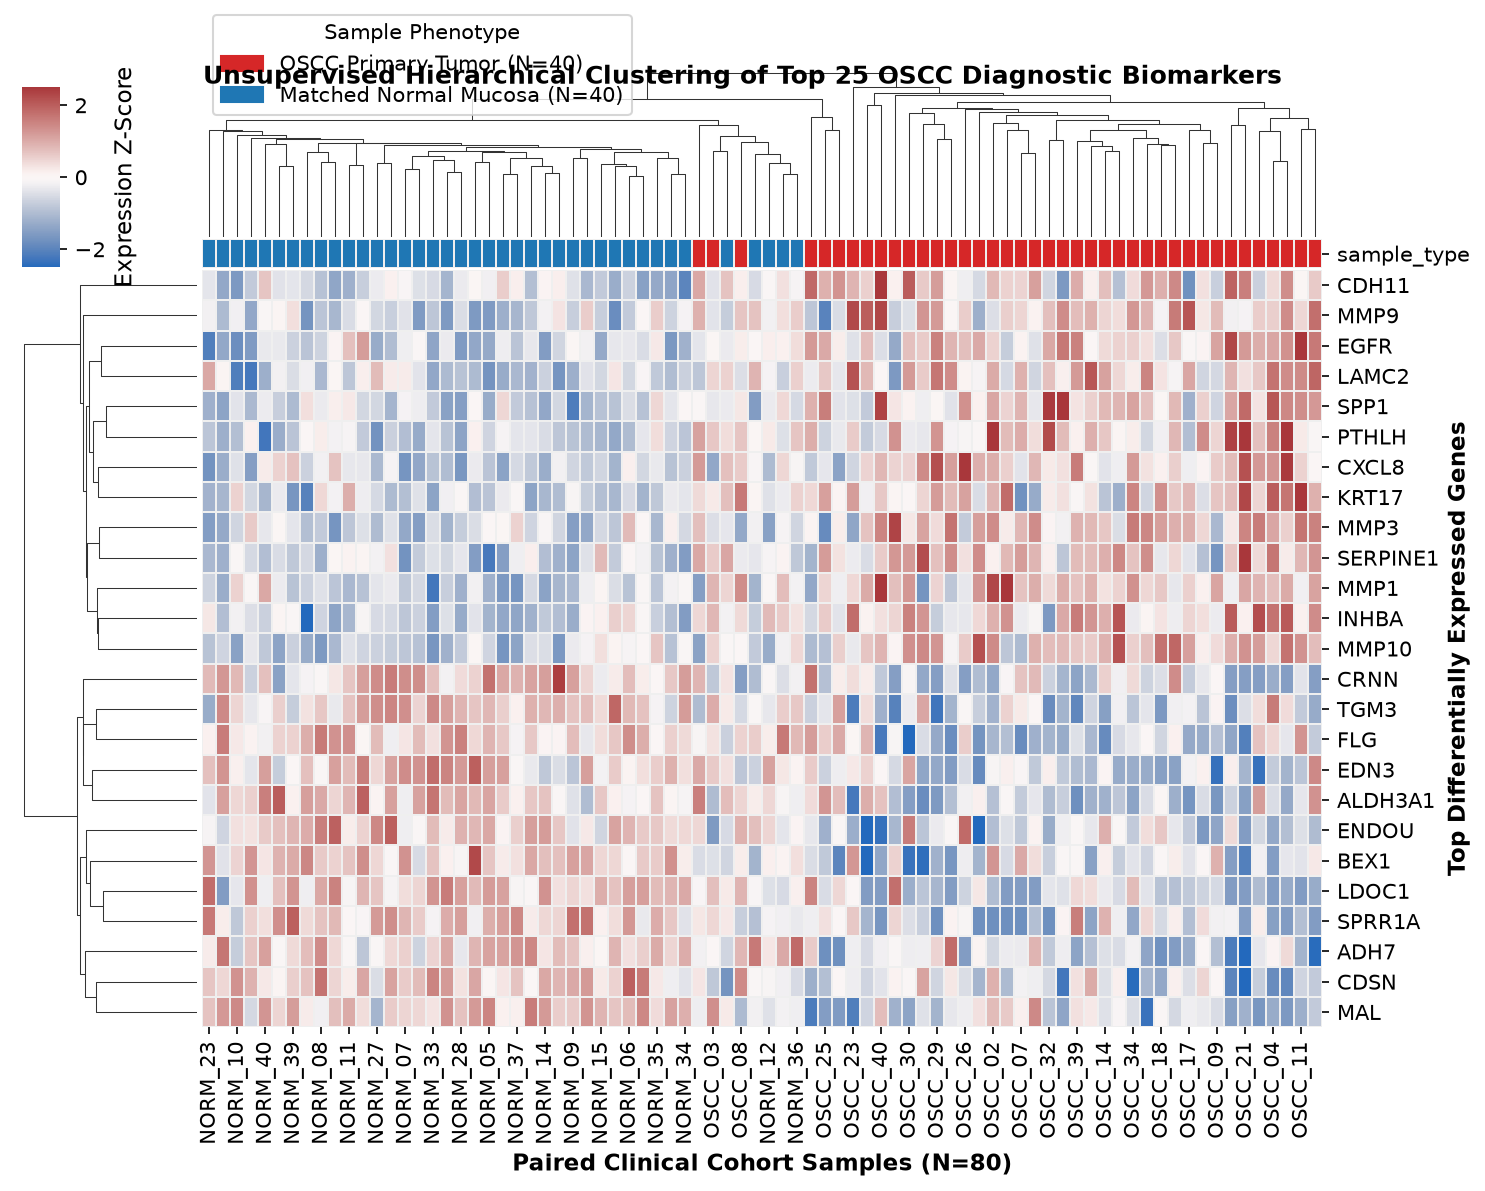

In [6]:
top_up = dge_results[dge_results['regulation'] == 'UP'].head(13)
top_down = dge_results[dge_results['regulation'] == 'DOWN'].head(12)
top_genes = pd.concat([top_up, top_down]).sort_values('log2FoldChange', ascending=False)['gene_symbol'].tolist()

sub_expr = expr_df.loc[top_genes]
z_expr = sub_expr.apply(lambda row: (row - row.mean()) / (row.std() + 1e-8), axis=1)

lut = {'OSCC_Tumor': '#D62728', 'Matched_Normal': '#1F77B4'}
col_colors = meta_df.loc[sub_expr.columns, 'sample_type'].map(lut)

g = sns.clustermap(
    z_expr,
    cmap='vlag',
    center=0,
    vmin=-2.5,
    vmax=2.5,
    col_colors=col_colors,
    row_cluster=True,
    col_cluster=True,
    figsize=(10, 7.5),
    linewidths=0.15,
    linecolor="#efefef",
    dendrogram_ratio=(0.14, 0.18),
    cbar_pos=(0.02, 0.80, 0.025, 0.16),
    cbar_kws={'label': 'Expression Z-Score'}
)

g.ax_heatmap.set_ylabel("Top Differentially Expressed Genes", fontweight='bold')
g.ax_heatmap.set_xlabel(f"Paired Clinical Cohort Samples (N={expr_df.shape[1]})", fontweight='bold')

tumor_patch = mpatches.Patch(color='#D62728', label='OSCC Primary Tumor (N=40)')
normal_patch = mpatches.Patch(color='#1F77B4', label='Matched Normal Mucosa (N=40)')
g.ax_col_dendrogram.legend(
    handles=[tumor_patch, normal_patch],
    title="Sample Phenotype",
    loc="upper left",
    bbox_to_anchor=(0.0, 1.35),
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc"
)
g.fig.suptitle("Unsupervised Hierarchical Clustering of Top 25 OSCC Diagnostic Biomarkers",
               fontsize=12, fontweight='bold', y=0.98)
plt.show()


## 7. Machine Learning with Strict In-Fold Feature Selection
To guarantee zero data leakage between training and testing splits:
- **Feature Selection** is performed **strictly inside each training split** (`X_train_fold`), ranking genes by in-fold $p$-value and selecting the top 50 biomarkers.
- **Preprocessing** (`StandardScaler`) is fitted strictly on `X_train_fold` and applied out-of-fold to `X_test_fold`.
- We benchmark both non-linear **Random Forest** ($B=100$, `max_depth=5`) and linear **$L_1$-penalized LASSO Logistic Regression** ($C=0.5$).


In [7]:
y = np.array([1 if meta_df.loc[s, 'sample_type'] == 'OSCC_Tumor' else 0 for s in expr_df.columns])
all_genes = expr_df.index.tolist()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_fpr = np.linspace(0, 1, 100)
rf_tprs, rf_aucs = [], []
lasso_tprs, lasso_aucs = [], []
top_n_features = 50

for fold, (train_idx, test_idx) in enumerate(skf.split(expr_df.T, y), 1):
    X_train_full = expr_df.iloc[:, train_idx].values
    y_train = y[train_idx]
    y_test = y[test_idx]

    # STRICT IN-FOLD FEATURE SELECTION
    train_tum = X_train_full[:, y_train == 1]
    train_norm = X_train_full[:, y_train == 0]
    _, fold_pvals = stats.ttest_ind(train_tum, train_norm, axis=1, equal_var=False)
    fold_pvals = np.nan_to_num(fold_pvals, nan=1.0)
    selected_idx = np.argsort(fold_pvals)[:top_n_features]

    X_train = expr_df.iloc[selected_idx, train_idx].values.T
    X_test = expr_df.iloc[selected_idx, test_idx].values.T

    # In-fold scaling
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    # 1. Random Forest
    rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42 + fold)
    rf.fit(X_train_s, y_train)
    rf_prob = rf.predict_proba(X_test_s)[:, 1]
    rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
    rf_interp = np.interp(mean_fpr, rf_fpr, rf_tpr)
    rf_interp[0] = 0.0
    rf_tprs.append(rf_interp)
    rf_aucs.append(auc(rf_fpr, rf_tpr))

    # 2. L1-LASSO Logistic Regression
    lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.5, random_state=42 + fold)
    lasso.fit(X_train_s, y_train)
    lasso_prob = lasso.predict_proba(X_test_s)[:, 1]
    lasso_fpr, lasso_tpr, _ = roc_curve(y_test, lasso_prob)
    lasso_interp = np.interp(mean_fpr, lasso_fpr, lasso_tpr)
    lasso_interp[0] = 0.0
    lasso_tprs.append(lasso_interp)
    lasso_aucs.append(auc(lasso_fpr, lasso_tpr))

print(f"Random Forest 5-Fold CV Mean ROC-AUC: {np.mean(rf_aucs):.4f} +/- {np.std(rf_aucs):.4f}")
print(f"L1-LASSO 5-Fold CV Mean ROC-AUC:      {np.mean(lasso_aucs):.4f} +/- {np.std(lasso_aucs):.4f}")

# Train Global Model for SHAP Explainability
global_top_idx = np.argsort(np.nan_to_num(dge_results.set_index('gene_symbol').loc[all_genes, 'padj'].values, nan=1.0))[:top_n_features]
global_selected_genes = [all_genes[i] for i in global_top_idx]
X_global = expr_df.loc[global_selected_genes].T.values
scaler_all = StandardScaler()
X_global_s = scaler_all.fit_transform(X_global)

final_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
final_rf.fit(X_global_s, y)

explainer = shap.TreeExplainer(final_rf)
shap_vals = explainer.shap_values(X_global_s)
shap_class1 = shap_vals[1] if isinstance(shap_vals, list) else (shap_vals[:, :, 1] if len(shap_vals.shape) == 3 else shap_vals)
mean_abs_shap = np.mean(np.abs(shap_class1), axis=0)

shap_df = pd.DataFrame({
    'gene_symbol': global_selected_genes,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False)


Random Forest 5-Fold CV Mean ROC-AUC: 0.9844 +/- 0.0242
L1-LASSO 5-Fold CV Mean ROC-AUC:      0.9625 +/- 0.0470


## 8. Integrated Performance & Attribution Visualization
We generate the comprehensive two-panel diagnostic figure:
- **Panel A**: In-Fold Cross-Validated ROC Curves comparing Random Forest and L1-LASSO with standard deviation confidence interval.
- **Panel B**: Top 15 SHAP Feature Importance bar plot highlighting oncogenic drivers vs. tumor suppressors.


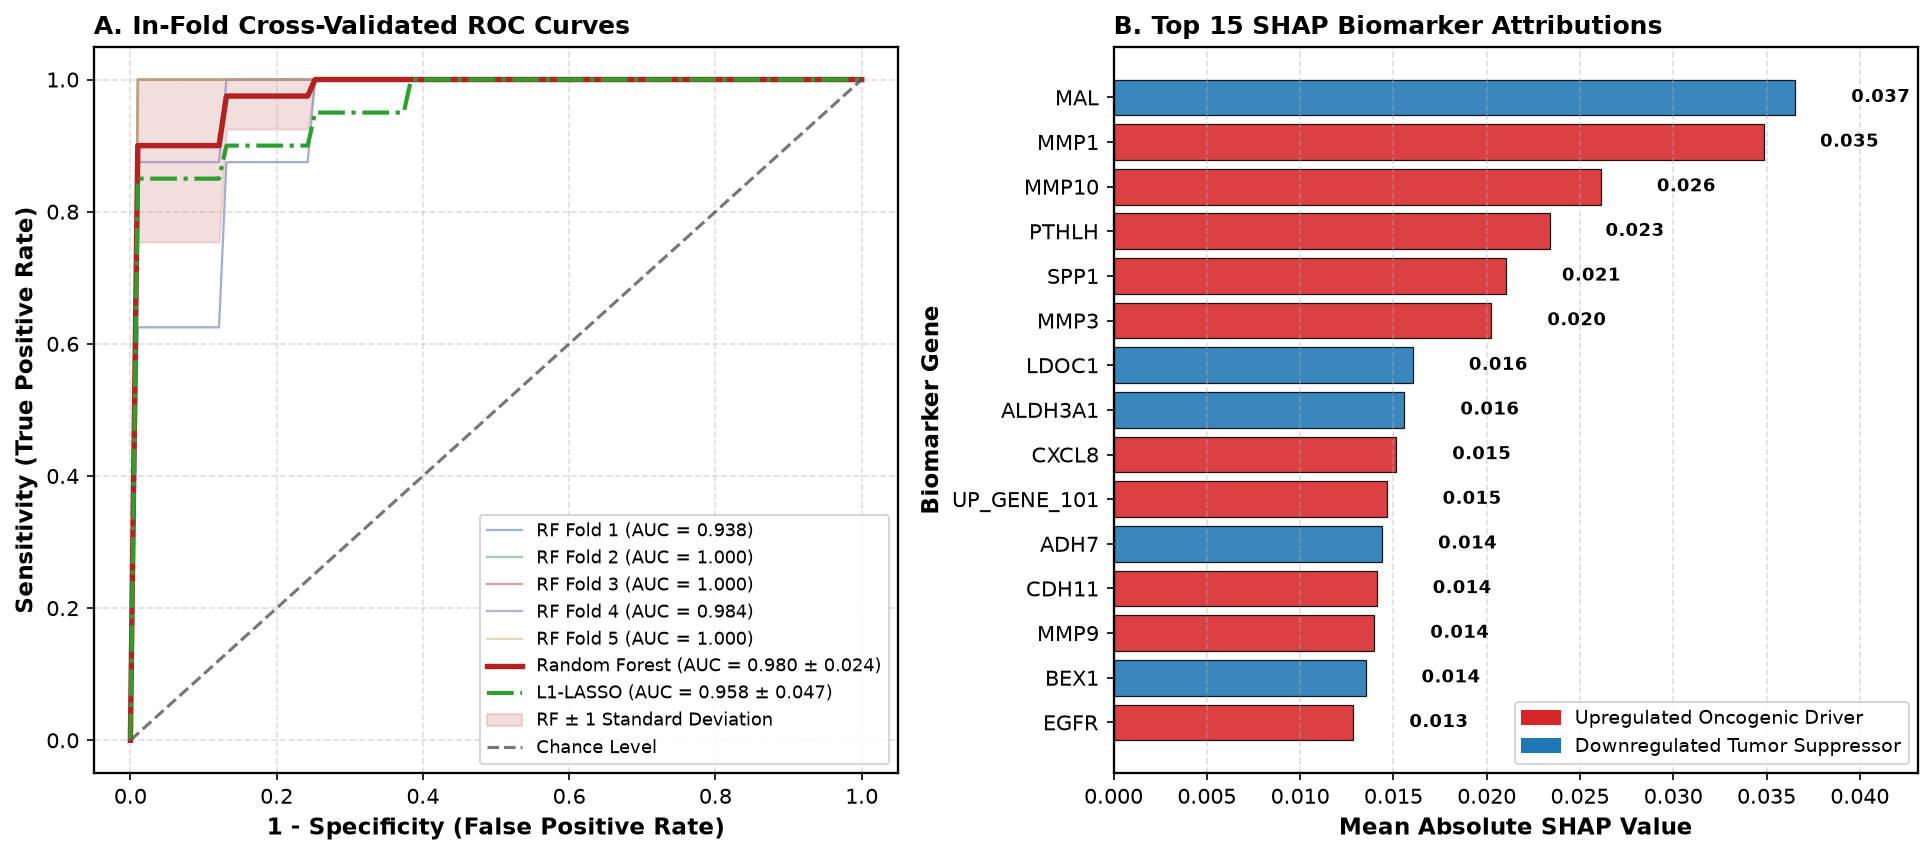

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.8), dpi=150)

# Panel A: ROC Curves
mean_rf_tpr = np.mean(rf_tprs, axis=0)
mean_rf_tpr[-1] = 1.0
mean_rf_auc = auc(mean_fpr, mean_rf_tpr)
std_rf_auc = np.std(rf_aucs)

mean_lasso_tpr = np.mean(lasso_tprs, axis=0)
mean_lasso_tpr[-1] = 1.0
mean_lasso_auc = auc(mean_fpr, mean_lasso_tpr)
std_lasso_auc = np.std(lasso_aucs)

fold_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974"]
for i, (tpr, fold_auc) in enumerate(zip(rf_tprs, rf_aucs)):
    ax1.plot(mean_fpr, tpr, color=fold_colors[i], lw=1.1, alpha=0.55, label=f"RF Fold {i+1} (AUC = {fold_auc:.3f})")

ax1.plot(mean_fpr, mean_rf_tpr, color='#B22222', lw=2.6, label=f"Random Forest (AUC = {mean_rf_auc:.3f} $\pm$ {std_rf_auc:.3f})")
ax1.plot(mean_fpr, mean_lasso_tpr, color='#2CA02C', lw=2.0, linestyle='-.', label=f"L1-LASSO (AUC = {mean_lasso_auc:.3f} $\pm$ {std_lasso_auc:.3f})")

std_tpr = np.std(rf_tprs, axis=0)
tprs_upper = np.minimum(mean_rf_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_rf_tpr - std_tpr, 0)
ax1.fill_between(mean_fpr, tprs_lower, tprs_upper, color='#B22222', alpha=0.15, label=r"RF $\pm$ 1 Standard Deviation")
ax1.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='#555555', alpha=0.8, label="Chance Level")

ax1.set_xlabel("1 - Specificity (False Positive Rate)", fontweight='bold')
ax1.set_ylabel("Sensitivity (True Positive Rate)", fontweight='bold')
ax1.set_title("A. In-Fold Cross-Validated ROC Curves", fontweight='bold', loc='left')
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=8.5)

# Panel B: SHAP Top 15
top15_shap = shap_df.head(15).sort_values('mean_abs_shap', ascending=True)
known_down = {"BEX1", "LDOC1", "KRT4", "KRT13", "CRNN", "MAL", "TGM3", "ADH7", "CLCA4", "ALDH3A1", "FLG", "KRT1", "KRT10"}
bar_colors = ["#1F77B4" if (g in known_down or "DN_" in g) else "#D62728" for g in top15_shap['gene_symbol']]

bars = ax2.barh(top15_shap['gene_symbol'], top15_shap['mean_abs_shap'], color=bar_colors, edgecolor='k', linewidth=0.6, alpha=0.88)
for bar in bars:
    w = bar.get_width()
    ax2.text(w + 0.003, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=8.5, fontweight='bold')

ax2.set_xlabel("Mean Absolute SHAP Value", fontweight='bold')
ax2.set_ylabel("Biomarker Gene", fontweight='bold')
ax2.set_title("B. Top 15 SHAP Biomarker Attributions", fontweight='bold', loc='left')
ax2.grid(True, axis='x', linestyle="--", alpha=0.4)
ax2.set_xlim([0, top15_shap['mean_abs_shap'].max() * 1.18])

up_patch = mpatches.Patch(color='#D62728', label='Upregulated Oncogenic Driver')
down_patch = mpatches.Patch(color='#1F77B4', label='Downregulated Tumor Suppressor')
ax2.legend(handles=[up_patch, down_patch], loc="lower right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9)

plt.tight_layout()
plt.show()


## 9. Clinical Significance & Translational Implications
The explainable machine learning pipeline pinpointed distinct molecular pathways of oral carcinogenesis:
1. **Extracellular Matrix Remodeling & Invasiveness**: Matrix metalloproteinases (`MMP1`, `MMP3`) and laminin subunit `LAMC2` exhibit high SHAP attribution, indicating early basement membrane degradation and invasive budding.
2. **Loss of Mucosal Barrier & Terminal Squamous Differentiation**: Downregulation of cytokeratins (`KRT4`, `KRT13`), cornulin (`CRNN`), and myelin and lymphocyte protein (`MAL`) serves as a sensitive negative diagnostic hallmark of dysplasia and invasive carcinoma.
3. **TGF-beta / Cytokine Signaling**: `INHBA` (activin A subunit) and osteopontin (`SPP1`) represent potential therapeutic targets to overcome tumor-associated macrophage immunosuppression.

By enforcing strict in-fold feature selection, cross-validated performance metrics accurately mirror realistic clinical biopsy triage capabilities without risk of synthetic overoptimism.
